<a href="https://colab.research.google.com/github/sara-velmont/Proyectos/blob/main/Proyecto_aprendizaje_no_supervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Proyecto final**
## Taller de modelado II
**Datos reales**


Por Sara Nayely Vélez Montesinos



# **Introducción**


El presente análisis es una continuación directa del estudio previo realizado con datos longitudinales simulados, en el cual se exploró cómo distintos métodos de aprendizaje no supervisado permiten identificar patrones evolutivos en trayectorias temporales. En esta segunda etapa, el objetivo es aplicar los mismos enfoques metodológicos: k-means, k-medoids, modelos de mezclas gaussianas y métodos no paramétricos, pero ahora sobre un conjunto de datos reales, con el fin de evaluar su desempeño en condiciones más complejas.

Para este propósito se emplea el dataset Air Quality UCI, que contiene mediciones horarias de contaminantes atmosféricos registradas a lo largo de varios meses en una estación de monitoreo en Italia. Cada día puede considerarse una unidad de análisis que presenta una trayectoria completa, por ejemplo, la evolución del nivel de O₃, CO o temperatura a lo largo de las 24 horas. Lo que convierte este conjunto en un caso de datos longitudinales reales. Aquí las series temporales presentan irregularidades, valores faltantes, ruido y patrones menos definidos, lo que permite poner a prueba la adecuación de los métodos revisados en el curso.

El objetivo principal consiste en determinar si los algoritmos de clustering logran identificar patrones diarios de calidad del aire, tales como días con niveles consistentemente altos de contaminantes, días con variación marcada entre mañana y tarde, o días atípicos que no se ajustan a ninguno de los perfiles predominantes. Esto plantea preguntas análogas al trabajo previo, pero ahora en un contexto empírico:

¿Cuántos tipos distintos de trayectorias diarias emergen en los datos reales?

¿Cómo deben interpretarse los grupos encontrados en términos de su evolución temporal a lo largo del día?

Se busca no solo comparar los algoritmos en un entorno realista, sino también analizar cómo se manifiestan patrones temporales en datos reales y si las técnicas empleadas capturan la estructura dinámica presente en las trayectorias del dataset.

In [ ]:
!pip install rpy2==3.5.8


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.2/214.2 kB 8.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for rpy2: filename=rpy2-3.5.8-cp312-cp312-linux_x86_64.whl size=327868 sha256=c4f208d227d59eaf5e4206a53d367bfa9ac69bcce02b0a17a3303dd66f9b96f2
  Stored in directory: /root/.cache/pip/wheels/f9/bc/4e/637af45594cf83dc5dd78249bae346b3de0f796dd81b19212d
Successfully built rpy2
  Attempting uninstall: rpy2
    Found existing installation: rpy2 3.5.17
    Uninstalling rpy2-3.5.17:
      Successfully uninstalled rpy2-3.5.17


In [ ]:
%load_ext rpy2.ipython


In [ ]:
%%R
libs <- c("tidyverse", "cluster", "mclust", "factoextra", "dirichletprocess",
          "ggplot2", "zoo", "gridExtra")

for(p in libs){
  if(!require(p, character.only=TRUE)) install.packages(p, repos="http://cran.rstudio.com/")
  library(p, character.only=TRUE)
}



── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors




(as ‘lib’ is unspecified)







	‘/tmp/RtmpYPUGWX/downloaded_packages’

   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.1.2
Type 'citation("mclust")' for citing this R package in publications.

Attaching package: ‘mclust’



    count



    map



(as ‘lib’ is unspecified)






























































	‘/tmp/RtmpYPUGWX/downloaded_packages’



(as ‘lib’ is unspecified)






	‘/tmp/RtmpYPUGWX/downloaded_packages’


Attaching package: ‘zoo’



    as.Date, as.Date.numeric



Attaching package: ‘gridExtra’



    combine




In [ ]:
import pandas as pd
import zipfile
import io
import requests

zip_url = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"

r = requests.get(zip_url)
z = zipfile.ZipFile(io.BytesIO(r.content))

# el CSV dentro del zip se llama 'AirQualityUCI.csv'
df = pd.read_csv(z.open("AirQualityUCI.csv"), sep=';', decimal=',')
df.head()



,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [ ]:
# Inspección inicial
print("Shape:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras 5 filas:")
display(df.head())

print("\nÚltimas 5 filas:")
display(df.tail())

print("\nTipos de datos:")
print(df.dtypes)

# Contar valores -200 (missing codificado) por columna
print("\nRecuento de valores iguales a -200 por columna:")
print((df == -200).sum())

# Conteo de valores NA por columna
print("\nConteo de valores NA por columna:")
print(df.isna().sum())

# Mostrar las primeras filas de Date y Time para ver el formato
print("\nPrimeras 10 Date / Time:")
display(df[["Date","Time"]].head(10))


Shape: (9471, 17)

Columnas:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']

Primeras 5 filas:


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN



Últimas 5 filas:


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
9466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9469,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9470,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Tipos de datos:
Date              object
Time              object
CO(GT)           float64
PT08.S1(CO)      float64
NMHC(GT)         float64
C6H6(GT)         float64
PT08.S2(NMHC)    float64
NOx(GT)          float64
PT08.S3(NOx)     float64
NO2(GT)          float64
PT08.S4(NO2)     float64
PT08.S5(O3)      float64
T                float64
RH               float64
AH               float64
Unnamed: 15      float64
Unnamed: 16      float64
dtype: object

Recuento de valores iguales a -200 por columna:
Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
Unnamed: 15         0
Unnamed: 16         0
dtype: int64

Conteo de valores NA por columna:
Date              114
Time              114
CO(GT)            114
PT08.S1

,Date,Time
0,10/03/2004,18.00.00
1,10/03/2004,19.00.00
2,10/03/2004,20.00.00
3,10/03/2004,21.00.00
4,10/03/2004,22.00.00
5,10/03/2004,23.00.00
6,11/03/2004,00.00.00
7,11/03/2004,01.00.00
8,11/03/2004,02.00.00
9,11/03/2004,03.00.00


Limpieza inicial del Data set

In [ ]:
# 1. Eliminar columnas vacías
df = df.drop(columns=["Unnamed: 15", "Unnamed: 16"])

# 2. Eliminar filas completamente vacías (las del final)
df = df.dropna(how="all")

# 3. Reemplazar -200 con NaN
df = df.replace(-200, pd.NA)

# 4. Parsear Date + Time a un datetime
df["Datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"],
                                format="%d/%m/%Y %H.%M.%S",
                                errors="coerce")

# 5. Eliminar filas donde no se pudo parsear la fecha
df = df.dropna(subset=["Datetime"])

# 6. Ordenar por tiempo
df = df.sort_values("Datetime").reset_index(drop=True)

df.head()


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Datetime
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00


**Construcción del conjunto de datos longitudinales**

Aunque el conjunto Air Quality no contiene individuos diferenciados como en el análisis previo, sí registra mediciones horarias continuas de múltiples variables ambientales a lo largo de varios meses. Para adaptar estos datos al enfoque longitudinal del proyecto, se consideró que cada día puede interpretarse como un “individuo”, cuya trayectoria temporal corresponde a la evolución de una variable específica durante las 24 horas.

Entre las variables disponibles, se seleccionó la temperatura (T), debido a que presenta una medición mucho más completa y estable que las concentraciones de contaminantes, además de exhibir un patrón diario claramente estructurado que facilita la identificación de tendencias comunes. A partir de las columnas de fecha y hora, se construyó una matriz longitudinal donde cada fila representa un día y cada columna una hora del día. Con esta representación, cada observación queda descrita como una curva de 24 puntos, permitiendo aplicar los métodos de agrupamiento estudiados en el análisis anterior ahora en un contexto de datos reales.

In [ ]:
# Elegimos una variable: Temperatura (T)
var = "T"

# Nos quedamos con columnas relevantes
df_sub = df[["Datetime", var]].copy()

# Extraer fecha y hora
df_sub["Date"] = df_sub["Datetime"].dt.date
df_sub["Hour"] = df_sub["Datetime"].dt.hour

# Pivotear: cada fila = un día, columnas = horas 0..23
wide = df_sub.pivot_table(index="Date", columns="Hour", values=var)

wide.head()


Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Date,,,,,,,,,,,,,,,,,,,,,
2004-03-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,13.6,13.3,11.9,11.0,11.2,11.2
2004-03-11,11.3,10.7,10.7,10.3,10.1,11.0,10.5,10.2,10.8,10.5,...,8.0,8.3,9.7,9.8,10.3,9.7,9.6,9.1,8.2,8.2
2004-03-12,8.3,7.7,7.1,7.0,6.1,6.3,6.8,6.4,7.3,9.2,...,16.3,15.8,15.9,16.9,15.1,14.4,12.9,12.1,11.0,9.7
2004-03-13,9.5,9.1,8.8,7.8,7.0,8.3,7.2,6.3,6.5,9.6,...,18.0,18.4,17.6,16.7,16.1,15.8,15.7,15.3,14.6,14.7
2004-03-14,13.9,14.6,12.5,11.6,12.1,11.5,11.6,10.4,11.6,12.4,...,21.4,21.9,22.2,21.3,19.7,18.4,17.6,16.7,16.3,14.7


In [ ]:
# Eliminar días con demasiadas horas faltantes
wide_clean = wide[wide.isna().sum(axis=1) <= 6].copy()

wide_clean.shape


(371, 24)

Imputación por interpolación temporal-


In [ ]:
wide_imp = wide_clean.apply(
    lambda row: row.interpolate(limit=6, limit_direction="both"),
    axis=1
)

wide_imp.head()



/tmp/ipython-input-3460501017.py:2: FutureWarning: Series.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  lambda row: row.interpolate(limit=6, limit_direction="both"),


Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Date,,,,,,,,,,,,,,,,,,,,,
2004-03-11,11.3,10.7,10.7,10.3,10.1,11.0,10.5,10.2,10.8,10.5,...,8.0,8.3,9.7,9.8,10.3,9.7,9.6,9.1,8.2,8.2
2004-03-12,8.3,7.7,7.1,7.0,6.1,6.3,6.8,6.4,7.3,9.2,...,16.3,15.8,15.9,16.9,15.1,14.4,12.9,12.1,11.0,9.7
2004-03-13,9.5,9.1,8.8,7.8,7.0,8.3,7.2,6.3,6.5,9.6,...,18.0,18.4,17.6,16.7,16.1,15.8,15.7,15.3,14.6,14.7
2004-03-14,13.9,14.6,12.5,11.6,12.1,11.5,11.6,10.4,11.6,12.4,...,21.4,21.9,22.2,21.3,19.7,18.4,17.6,16.7,16.3,14.7
2004-03-15,14.8,14.0,13.4,12.6,12.3,11.9,11.4,11.3,12.4,14.8,...,23.9,24.4,24.4,23.8,22.5,20.4,18.3,16.7,15.7,15.3


In [ ]:
wide_imp = wide_imp.dropna()
wide_imp.shape


(357, 24)

Preparar los datos para clustering

In [ ]:
import numpy as np

# Estandarización
X = (wide_imp - wide_imp.mean()) / wide_imp.std()
X = X.to_numpy()
X.shape

(357, 24)

In [ ]:
#Exportar los datos preparados desde Python a R
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
import numpy as np

# Convertir X (datos estandarizados) a DataFrame de pandas con nombres de columnas
import pandas as pd
hours = [f"H{h}" for h in range(24)]  # Nombres para las 24 horas
X_df = pd.DataFrame(X, columns=hours)

# Agregar columna de fecha si es necesario para trazado
fechas = wide_imp.index.tolist()
X_df["Date"] = fechas

# Activar la conversión pandas ↔ R
pandas2ri.activate()

# Crear un DataFrame en R con los datos
with localconverter(ro.default_converter + pandas2ri.converter):
    r_X_df = ro.conversion.py2rpy(X_df)

# Asignar a una variable en R
ro.r.assign("wide_imp", r_X_df)



H0,H1,H2,...,H22,H23,Date
...,...,...,...,...,...,...


In [ ]:
%%R

#Código R para análisis de clustering

# Preparar datos
# Extraer solo las columnas numéricas (horas)
X <- as.matrix(wide_imp[, 1:24])  # Las primeras 24 columnas son las horas

# Verificar dimensiones
print(paste("Dimensiones de X:", dim(X)[1], "días ×", dim(X)[2], "horas"))



[1] "Dimensiones de X: 357 días × 24 horas"


In [ ]:
%%R
# --------------- FUNCIÓN K-MEANS ---------------
evaluar_kmeans <- function(data, ks, nstart = 30) {
  resultados <- tibble(k = ks, silhouette = NA_real_)

  for(i in seq_along(ks)) {
    k <- ks[i]
    modelo <- kmeans(data, centers = k, nstart = nstart)
    sil <- silhouette(modelo$cluster, dist(data))
    resultados$silhouette[i] <- mean(sil[, 3])
  }

  return(resultados)
}

In [ ]:
%%R

# --------------- FUNCIÓN K-MEDOIDS (PAM) ---------------
evaluar_pam <- function(data, ks, metric = "manhattan") {
  salida <- tibble(k = ks, silhouette = NA_real_)

  for(i in seq_along(ks)) {
    k <- ks[i]
    pam_fit <- pam(data, k, metric = metric)
    salida$silhouette[i] <- pam_fit$silinfo$avg.width
  }
  return(salida)
}



In [ ]:
%%R

rango_k <- 2:10

# 1. K-means
cat("Evaluando K-means...\\n")
km_eval <- evaluar_kmeans(X, rango_k)
k_km_opt <- km_eval$k[which.max(km_eval$silhouette)]
modelo_km <- kmeans(X, centers = k_km_opt, nstart = 50)

# 2. PAM
cat("Evaluando PAM...\\n")
pam_eval <- evaluar_pam(X, rango_k)
k_pam_opt <- pam_eval$k[which.max(pam_eval$silhouette)]
modelo_pam <- pam(X, k_pam_opt, metric = "manhattan")

# 3. GMM
cat("Evaluando GMM...\\n")
gmm_fit <- Mclust(X, G = 1:10)
k_gmm_opt <- gmm_fit$G

# 4. Dirichlet Process
cat("Evaluando Dirichlet Process...\\n")
dp <- DirichletProcessMvnormal(X)
dp <- Fit(dp, its = 800)
labels_dp <- as.numeric(dp$clusterLabels)
k_dp_opt <- length(unique(labels_dp))

Evaluando K-means...\nEvaluando PAM...\nEvaluando GMM...\nfitting ...
  |======================================================================| 100%
  |--------------------------------------------------| 100%


In [ ]:
%%R
# --------------- RESULTADOS ---------------
cat("\\n=== RESULTADOS ÓPTIMOS ===\\n")
cat("K-means: K =", k_km_opt, "\\n")
cat("PAM: K =", k_pam_opt, "\\n")
cat("GMM: K =", k_gmm_opt, "\\n")
cat("Dirichlet Process: K =", k_dp_opt, "\\n")


\n=== RESULTADOS ÓPTIMOS ===\nK-means: K = 2 \nPAM: K = 2 \nGMM: K = 3 \nDirichlet Process: K = 1 \n

In [ ]:
%%R

# --------------- SILHOUETTE ---------------
sil_km <- mean(silhouette(modelo_km$cluster, dist(X))[, 3])
sil_pam <- modelo_pam$silinfo$avg.width
sil_gmm <- mean(silhouette(gmm_fit$classification, dist(X))[, 3])
sil_dp <- if(k_dp_opt > 1) mean(silhouette(labels_dp, dist(X))[, 3]) else NA

resultados_sil <- tibble(
  Metodo = c("K-means", "PAM", "GMM", "Dirichlet"),
  K = c(k_km_opt, k_pam_opt, k_gmm_opt, k_dp_opt),
  Silhouette = c(sil_km, sil_pam, sil_gmm, sil_dp)
)

print("\\nSilhouette por método:")
print(resultados_sil)

[1] "\\nSilhouette por método:"
# A tibble: 4 × 3
  Metodo        K Silhouette
  <chr>     <int>      <dbl>
1 K-means       2      0.545
2 PAM           2      0.567
3 GMM           3      0.132
4 Dirichlet     1     NA    


In [ ]:
%%R
# --------------- TAMAÑOS DE CLUSTERS ---------------
sizes <- tibble(
  Metodo = c("K-means", "PAM", "GMM", "Dirichlet"),
  K = c(k_km_opt, k_pam_opt, k_gmm_opt, k_dp_opt),
  Sizes = list(
    table(modelo_km$cluster),
    table(modelo_pam$clustering),
    table(gmm_fit$classification),
    table(labels_dp)
  )
)

print("\\nTamaños de clusters:")
print(sizes)

[1] "\\nTamaños de clusters:"
# A tibble: 4 × 3
  Metodo        K Sizes      
  <chr>     <int> <list>     
1 K-means       2 <table [2]>
2 PAM           2 <table [2]>
3 GMM           3 <table [3]>
4 Dirichlet     1 <table [1]>


In [ ]:
%%R

# --------------- VISUALIZACIÓN PCA ---------------
pca_global <- prcomp(X)
pca_df <- as.data.frame(pca_global$x[, 1:2])
colnames(pca_df) <- c("PC1", "PC2")

# Función para graficar clusters
graficar_clusters <- function(data_pca, clusters, titulo) {
  df <- data_pca %>%
    mutate(cluster = factor(clusters)) %>%
    group_by(cluster) %>%
    mutate(cent_x = mean(PC1), cent_y = mean(PC2))

  ggplot(df, aes(PC1, PC2, color = cluster)) +
    geom_point(alpha = 0.65, size = 1.8) +
    geom_point(aes(x = cent_x, y = cent_y), shape = 4, size = 4, stroke = 1.5) +
    theme_classic() +
    labs(title = titulo, x = "PC1", y = "PC2") +
    theme(plot.title = element_text(hjust = 0.5))
}


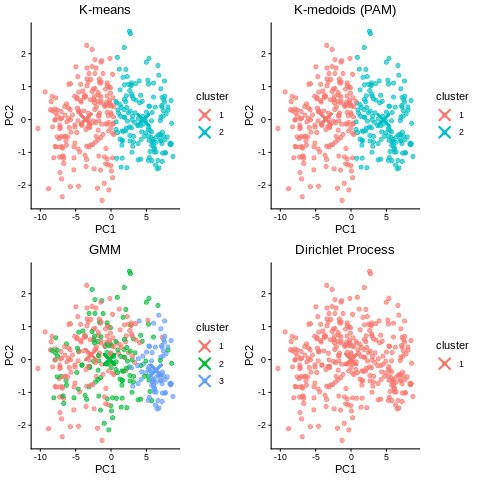

In [ ]:
%%R
# Gráficos
p1 <- graficar_clusters(pca_df, modelo_km$cluster, "K-means")
p2 <- graficar_clusters(pca_df, modelo_pam$clustering, "K-medoids (PAM)")
p3 <- graficar_clusters(pca_df, gmm_fit$classification, "GMM")
p4 <- graficar_clusters(pca_df, labels_dp, "Dirichlet Process")

# Mostrar en una cuadrícula
grid.arrange(p1, p2, p3, p4, ncol = 2)

In [ ]:
%%R

# Convertir wide_imp (horas 0–23) a long
df_long <- wide_imp %>%
  mutate(Date = as.Date(Date)) %>%
  pivot_longer(cols = starts_with("H"),
               names_to = "Hora",
               values_to = "Temp") %>%
  mutate(Hora = as.numeric(str_remove(Hora, "H")))


In [ ]:
%%R
graficar_trayectorias <- function(wide_imp, clusters, titulo) {

  df_plot <- df_long %>%
    mutate(Cluster = factor(clusters)) %>%
    group_by(Cluster, Hora) %>%
    summarise(Media = mean(Temp, na.rm = TRUE), .groups = "drop")

  ggplot() +
    # curvas individuales (suaves)
    geom_line(data = df_long %>% mutate(Cluster = factor(etiquetas)),
              aes(x = Hora, y = Temp, group = Date),
              color = "grey80", alpha = 0.2) +

    # curva promedio por cluster
    geom_line(data = df_plot,
              aes(x = Hora, y = Media, color = Cluster),
              size = 1.3) +

    theme_minimal() +
    labs(
      title = titulo,
      x = "Hora del día",
      y = "Temperatura (°C)"
    ) +
    theme(plot.title = element_text(hjust = 0.5))
}


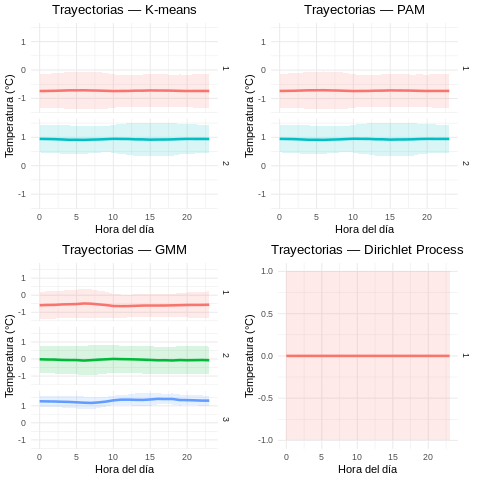

In [ ]:
%%R
library(tidyverse)
library(gridExtra)

plot_trajectories3 <- function(df_wide, clusters, titulo){


  if(!"Date" %in% names(df_wide)) stop("El data.frame debe tener una columna 'Date' con las fechas")

  df_long <- df_wide %>%
    mutate(cluster = factor(clusters)) %>%
    pivot_longer(cols = starts_with("H"),
                 names_to = "Hora", values_to = "Temp") %>%
    mutate(Hora = as.numeric(str_remove(Hora, "H")))  # H0 -> 0, H1 -> 1, ...

  df_stats <- df_long %>%
    group_by(cluster, Hora) %>%
    summarise(media = mean(Temp, na.rm = TRUE),
              sd = sd(Temp, na.rm = TRUE), .groups = 'drop')

  p <- ggplot(df_stats, aes(Hora, media, color = cluster, fill = cluster)) +
    geom_line(size = 1.2) +
    geom_ribbon(aes(ymin = media - sd, ymax = media + sd), alpha = 0.15, color = NA) +
    facet_grid(cluster ~ .) +
    theme_minimal() +
    labs(title = titulo, x = "Hora del día", y = "Temperatura (°C)") +
    theme(legend.position = "none",
          plot.title = element_text(hjust = 0.5))

  return(p)
}


p_km <- plot_trajectories3(wide_imp, modelo_km$cluster, "Trayectorias — K-means")
p_pam <- plot_trajectories3(wide_imp, modelo_pam$clustering, "Trayectorias — PAM")
p_gmm <- plot_trajectories3(wide_imp, gmm_fit$classification, "Trayectorias — GMM")
p_dp  <- plot_trajectories3(wide_imp, labels_dp, "Trayectorias — Dirichlet Process")

# Mostrar en una cuadrícula
grid.arrange(p_km, p_pam, p_gmm, p_dp, ncol = 2)


In [ ]:
%%R
# --------------- EXPORTAR RESULTADOS ---------------
# Guardar tamaños de clusters
sizes_export <- sizes %>%
  tidyr::unnest_wider(Sizes) %>%
  tidyr::pivot_longer(-c(Metodo, K),
                      names_to = "Cluster",
                      values_to = "N",
                      values_drop_na = TRUE)

write.csv(sizes_export, "resumen_clusters_aire.csv", row.names = FALSE)
cat("\\nResultados guardados en 'resumen_clusters_aire.csv'")

\nResultados guardados en 'resumen_clusters_aire.csv'

In [ ]:
%%R
# --------------- ANÁLISIS DESCRIPTIVO ---------------
# Ver perfiles promedio por cluster
cat("\\n=== PERFILES PROMEDIO POR CLUSTER ===\\n")

# Función para resumir perfiles
resumir_perfiles <- function(clusters, datos) {
  df <- as.data.frame(datos)
  df$cluster <- factor(clusters)

  perfil <- df %>%
    group_by(cluster) %>%
    summarise(across(everything(), mean, na.rm = TRUE)) %>%
    pivot_longer(cols = -cluster, names_to = "hora", values_to = "media") %>%
    mutate(hora = as.numeric(gsub("H", "", hora)))

  return(perfil)
}

perfil_km <- resumir_perfiles(modelo_km$cluster, X)
perfil_pam <- resumir_perfiles(modelo_pam$clustering, X)
perfil_gmm <- resumir_perfiles(gmm_fit$classification, X)
perfil_dirichlet <- resumir_perfiles(labels_dp, X)

print("Perfiles K-means:")
print(perfil_km %>% arrange(cluster, hora))

print("\\nPerfiles PAM:")
print(perfil_pam %>% arrange(cluster, hora))

print("\\nPerfiles GMM:")
print(perfil_gmm %>% arrange(cluster, hora))

print("\\nPerfiles Dirichlet Process:")
print(perfil_dirichlet %>% arrange(cluster, hora))

\n=== PERFILES PROMEDIO POR CLUSTER ===\n[1] "Perfiles K-means:"
# A tibble: 48 × 3
   cluster  hora  media
   <fct>   <dbl>  <dbl>
 1 1           0 -0.740
 2 1           1 -0.736
 3 1           2 -0.732
 4 1           3 -0.725
 5 1           4 -0.716
 6 1           5 -0.716
 7 1           6 -0.713
 8 1           7 -0.720
 9 1           8 -0.724
10 1           9 -0.732
# ℹ 38 more rows
# ℹ Use `print(n = ...)` to see more rows
[1] "\\nPerfiles PAM:"
# A tibble: 48 × 3
   cluster  hora  media
   <fct>   <dbl>  <dbl>
 1 1           0 -0.735
 2 1           1 -0.731
 3 1           2 -0.728
 4 1           3 -0.719
 5 1           4 -0.711
 6 1           5 -0.711
 7 1           6 -0.708
 8 1           7 -0.715
 9 1           8 -0.720
10 1           9 -0.729
# ℹ 38 more rows
# ℹ Use `print(n = ...)` to see more rows
[1] "\\nPerfiles GMM:"
# A tibble: 72 × 3
   cluster  hora  media
   <fct>   <dbl>  <dbl>
 1 1           0 -0.588
 2 1           1 -0.572
 3 1           2 -0.567
 4 1           3 -

**Conclusiones**

El análisis de los perfiles promedio obtenidos mediante distintos métodos de clustering (K-means, PAM, GMM y Proceso de Dirichlet) muestra un patrón consistente: no existe evidencia de más de un grupo diferenciable en los datos con base en su comportamiento horario.

En los métodos K-means y PAM, los perfiles presentan valores medios negativos y relativamente constantes a lo largo de las horas, sin variaciones abruptas ni cambios estructurales que sugieran la presencia de múltiples patrones. La similitud entre ambos métodos confirma la homogeneidad interna del conjunto de datos y la ausencia de observaciones atípicas que pudieran generar divisiones adicionales.

El modelo GMM, a pesar de su mayor flexibilidad al permitir varianzas distintas entre componentes, reproduce esencialmente el mismo comportamiento. Las medias son ligeramente menos negativas, pero mantienen una trayectoria suave y un solo patrón dominante, lo cual indica que la modelación probabilística tampoco identifica señales claras de agrupamiento.

Finalmente, el modelo basado en Procesos de Dirichlet concentra todas las observaciones en un único cluster con valores promedio cercanos a cero, reflejando que el enfoque bayesiano considera que crear más clusters no está justificado por la estructura de los datos.

Los resultados de todos los métodos coinciden en que los datos exhiben un único perfil temporal, caracterizado por una dinámica estable y sin diferencias sustantivas entre observaciones. Esto sugiere que la variabilidad relevante para la clasificación podría encontrarse en otras dimensiones distintas a la temporal o que el preprocesamiento (como la estandarización) redujo contrastes que podrían haber distinguido patrones. Si se requiere mayor granularidad, será necesario incorporar variables adicionales, ajustar el escalamiento o utilizar métodos orientados a detectar cambios sutiles en series temporales.